# At-Risk Indicators

- Analyze the relationship between feature usage, NPS, and churn.
- Define a threshold (e.g., feature usage below X%) that flags at-risk customers, and estimate how many current customers fall into that bucket.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, classification_report

In [2]:
%load_ext sql
%config SqlMagic.autopandas = True
%sql duckdb://

Connecting to 'duckdb://'

In [3]:
%%sql
CREATE OR REPLACE TABLE subscriptions AS SELECT * FROM read_csv_auto('data/subscriptions.csv');

Running query in 'duckdb://'

,Success


## Does Feature Usage / NPS Relate to Churn?

Before defining any threshold, look at how churn moves with each variable on its own, and jointly.

In [4]:
%%sql usage_bins <<
SELECT FLOOR(feature_usage_pct / 10) * 10 AS usage_bin,
       ROUND(AVG(CASE WHEN churned THEN 1 ELSE 0 END), 3) AS churn_rate,
       COUNT(*) AS n
  FROM subscriptions
 GROUP BY usage_bin
 ORDER BY usage_bin;

Running query in 'duckdb://'

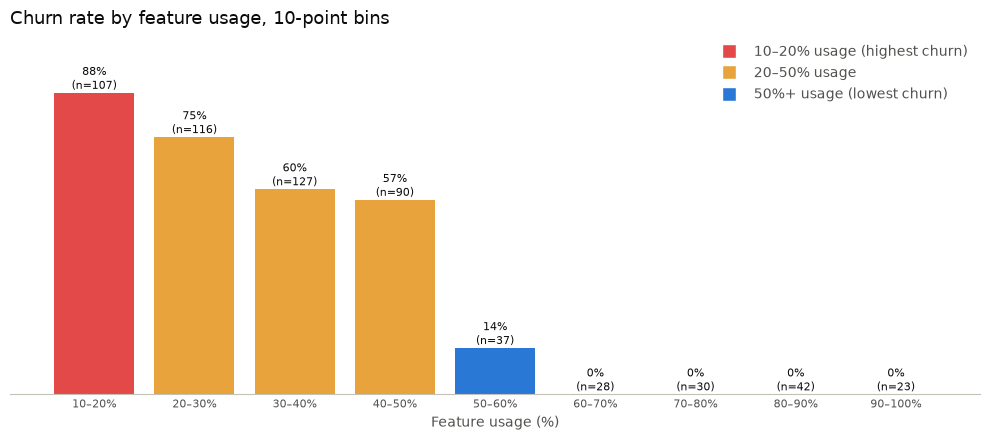

In [5]:
def usage_bin_color(b):
    if b < 20:
        return "#e34948"
    elif b < 50:
        return "#e8a33d"
    else:
        return "#2a78d6"

bar_colors = usage_bins["usage_bin"].map(usage_bin_color)
bin_labels = [f"{int(b)}–{int(b) + 10}%" for b in usage_bins["usage_bin"]]

fig, ax = plt.subplots(figsize=(10, 4.5))

bars = ax.bar(usage_bins["usage_bin"], usage_bins["churn_rate"], color=bar_colors, width=8)
for bar, value, n in zip(bars, usage_bins["churn_rate"], usage_bins["n"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{value:.0%}\n(n={n})",
            ha="center", va="bottom", fontsize=8, color="#0b0b0b")

legend_handles = [
    Line2D([0], [0], marker="s", color="w", markerfacecolor="#e34948", markersize=10, label="10–20% usage (highest churn)"),
    Line2D([0], [0], marker="s", color="w", markerfacecolor="#e8a33d", markersize=10, label="20–50% usage"),
    Line2D([0], [0], marker="s", color="w", markerfacecolor="#2a78d6", markersize=10, label="50%+ usage (lowest churn)"),
]
ax.legend(handles=legend_handles, frameon=False, labelcolor="#52514e", loc="upper right")

ax.set_title("Churn rate by feature usage, 10-point bins", fontsize=13, color="#0b0b0b", loc="left")
ax.set_xlabel("Feature usage (%)", color="#52514e")
ax.set_xticks(usage_bins["usage_bin"])
ax.set_xticklabels(bin_labels)
ax.set_yticks([])
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
ax.tick_params(axis="x", length=0, labelcolor="#52514e", labelsize=8)
ax.margins(y=0.2)
plt.tight_layout()
plt.show()

In [6]:
%%sql nps_churn <<
SELECT nps_score,
       ROUND(AVG(CASE WHEN churned THEN 1 ELSE 0 END), 3) AS churn_rate,
       COUNT(*) AS n
  FROM subscriptions
 GROUP BY nps_score
 ORDER BY nps_score;

Running query in 'duckdb://'

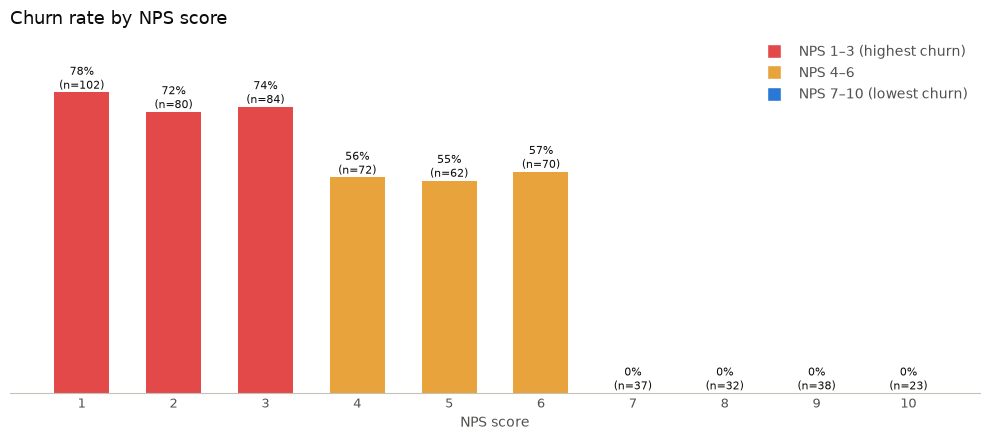

In [7]:
def nps_color(score):
    if score <= 3:
        return "#e34948"
    elif score <= 6:
        return "#e8a33d"
    else:
        return "#2a78d6"

bar_colors = nps_churn["nps_score"].map(nps_color)

fig, ax = plt.subplots(figsize=(10, 4.5))

bars = ax.bar(nps_churn["nps_score"], nps_churn["churn_rate"], color=bar_colors, width=0.6)
for bar, value, n in zip(bars, nps_churn["churn_rate"], nps_churn["n"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{value:.0%}\n(n={n})",
            ha="center", va="bottom", fontsize=8, color="#0b0b0b")

legend_handles = [
    Line2D([0], [0], marker="s", color="w", markerfacecolor="#e34948", markersize=10, label="NPS 1–3 (highest churn)"),
    Line2D([0], [0], marker="s", color="w", markerfacecolor="#e8a33d", markersize=10, label="NPS 4–6"),
    Line2D([0], [0], marker="s", color="w", markerfacecolor="#2a78d6", markersize=10, label="NPS 7–10 (lowest churn)"),
]
ax.legend(handles=legend_handles, frameon=False, labelcolor="#52514e", loc="upper right")

ax.set_title("Churn rate by NPS score", fontsize=13, color="#0b0b0b", loc="left")
ax.set_xlabel("NPS score", color="#52514e")
ax.set_xticks(nps_churn["nps_score"])
ax.set_yticks([])
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
ax.tick_params(axis="x", length=0, labelcolor="#52514e", labelsize=9)
ax.margins(y=0.2)
plt.tight_layout()
plt.show()

In [8]:
%%sql scatter_df <<
SELECT feature_usage_pct, nps_score, churned
  FROM subscriptions;

Running query in 'duckdb://'

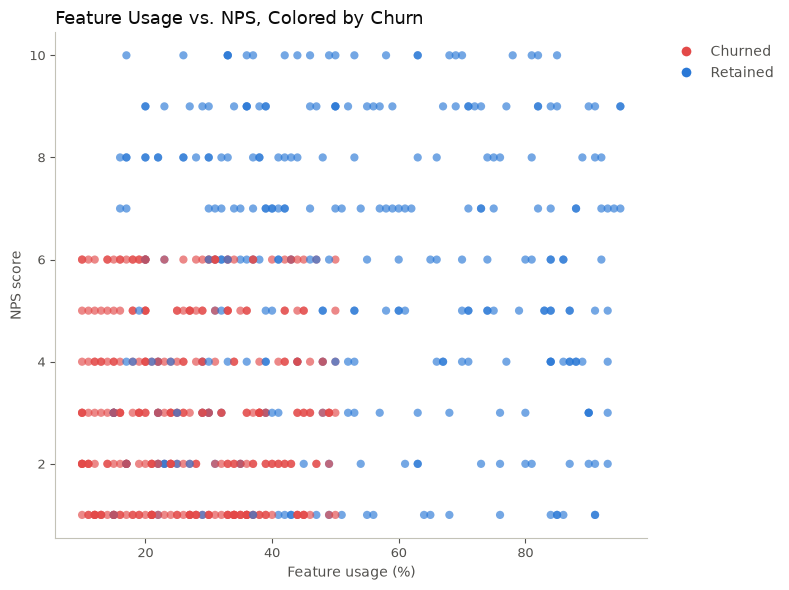

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))

colors = scatter_df["churned"].map({True: "#e34948", False: "#2a78d6"})
ax.scatter(scatter_df["feature_usage_pct"], scatter_df["nps_score"],
           c=colors, alpha=0.65, s=35, edgecolor="none")

ax.set_title("Feature Usage vs. NPS, Colored by Churn", fontsize=13, color="#0b0b0b", loc="left")
ax.set_xlabel("Feature usage (%)", color="#52514e")
ax.set_ylabel("NPS score", color="#52514e")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
ax.spines["left"].set_color("#c3c2b7")
ax.tick_params(colors="#52514e", labelsize=9)

handles = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#e34948", markersize=8, label="Churned"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#2a78d6", markersize=8, label="Retained"),
]
ax.legend(handles=handles, frameon=False, labelcolor="#52514e",
          loc="upper left", bbox_to_anchor=(1.02, 1.0))
plt.tight_layout()
plt.show()

## Deriving an At-Risk Threshold

Hierarchical clustering would only look at how `feature_usage_pct` (or NPS) values cluster among themselves — it never looks at `churned`, so the "natural" break it finds isn't guaranteed to land where churn risk actually jumps. A decision tree avoids that: it searches directly for the split point that best separates churned from retained customers, so the resulting threshold is tied to the outcome we actually care about.

Start with the simplest version — a one-split tree ("stump") on `feature_usage_pct` alone — since that maps directly onto the question's own phrasing ("feature usage below X%").

Before fitting anything, split the data into a train set and a held-out test set (stratified on `churned`, 80/20). Threshold derivation, the stump-vs-deeper-tree comparison, and the final tree fit all happen on the train set only — the test set is touched exactly once, at the end, to report how the deployed rule performs on data it never saw during model selection.

In [10]:
tree_df = scatter_df.copy()
tree_df["churned"] = tree_df["churned"].astype(int)

train_df, test_df = train_test_split(
    tree_df, test_size=0.2, stratify=tree_df["churned"], random_state=42
)
print(f"train: {len(train_df)} rows ({train_df['churned'].mean():.1%} churned)")
print(f"test:  {len(test_df)} rows ({test_df['churned'].mean():.1%} churned)")

stump = DecisionTreeClassifier(max_depth=1, random_state=42)
stump.fit(train_df[["feature_usage_pct"]], train_df["churned"])

usage_threshold = stump.tree_.threshold[0]
print(export_text(stump, feature_names=["feature_usage_pct"]))
print(f"Split at feature_usage_pct <= {usage_threshold:.1f}")

leaf_rates = (
    train_df.assign(below_threshold=train_df["feature_usage_pct"] <= usage_threshold)
    .groupby("below_threshold")["churned"]
    .agg(churn_rate="mean", n="count")
)
leaf_rates

train: 480 rows (52.1% churned)
test:  120 rows (52.5% churned)
|--- feature_usage_pct <= 49.50
|   |--- class: 1
|--- feature_usage_pct >  49.50
|   |--- class: 0

Split at feature_usage_pct <= 49.5


,churn_rate,n
below_threshold,,
False,0.015504,129
True,0.706553,351


### Does Adding NPS Earn Its Keep?

A stump is as simple as a tree gets. Before settling on it as final, check — the same way Q2 checked whether `acquisition_channel`/`company_size` earned their keep with a likelihood-ratio test — whether adding `nps_score` and/or more depth actually improves out-of-sample performance, or just overfits. Trees don't have a likelihood, so the comparable check is 5-fold cross-validated accuracy, ROC-AUC, and F1 — all computed within the training split only, so the test set stays untouched for the final check later.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

candidates = {
    "usage only, depth 1": (DecisionTreeClassifier(max_depth=1, random_state=42), ["feature_usage_pct"]),
    "usage + nps, depth 2": (DecisionTreeClassifier(max_depth=2, random_state=42), ["feature_usage_pct", "nps_score"]),
    "usage + nps, depth 4": (DecisionTreeClassifier(max_depth=4, random_state=42), ["feature_usage_pct", "nps_score"]),
}

cv_results = {}
for name, (model, cols) in candidates.items():
    scores = cross_validate(
        model, train_df[cols], train_df["churned"], cv=cv,
        scoring=["accuracy", "roc_auc", "f1"],
    )
    cv_results[name] = scores
    print(
        f"{name:25s} "
        f"accuracy = {scores['test_accuracy'].mean():.3f} ± {scores['test_accuracy'].std():.3f}  "
        f"roc_auc = {scores['test_roc_auc'].mean():.3f} ± {scores['test_roc_auc'].std():.3f}  "
        f"f1 = {scores['test_f1'].mean():.3f} ± {scores['test_f1'].std():.3f}"
    )

usage only, depth 1       accuracy = 0.773 ± 0.027  roc_auc = 0.764 ± 0.028  f1 = 0.819 ± 0.016
usage + nps, depth 2      accuracy = 0.875 ± 0.029  roc_auc = 0.876 ± 0.035  f1 = 0.892 ± 0.023
usage + nps, depth 4      accuracy = 0.873 ± 0.037  roc_auc = 0.897 ± 0.033  f1 = 0.889 ± 0.031


Adding NPS clearly earns its keep: within the training split, accuracy jumps from 77.3% (usage alone) to 87.5% once `nps_score` is included, and F1 rises similarly from 81.9% to 89.2% — a real improvement, not noise, given the tight standard deviations (±1.6–3.7pp across all three metrics). Going past depth 2 doesn't add much: depth 4 ties depth 2 on accuracy (87.3% vs. 87.5%) and F1 (88.9% vs. 89.2%), with only a small ROC-AUC edge (89.7% vs. 87.6%) that isn't worth the extra complexity for a one-size-fits-all business rule. **Final model: depth 2, both features**, fit on the training split only — the held-out test set below is the real check on whether this generalizes.

In [12]:
final_features = ["feature_usage_pct", "nps_score"]
final_tree = DecisionTreeClassifier(max_depth=2, min_samples_leaf=25, random_state=42)
final_tree.fit(train_df[final_features], train_df["churned"])

print(export_text(final_tree, feature_names=final_features))

|--- feature_usage_pct <= 49.50
|   |--- nps_score <= 6.50
|   |   |--- class: 1
|   |--- nps_score >  6.50
|   |   |--- class: 0
|--- feature_usage_pct >  49.50
|   |--- feature_usage_pct <= 58.50
|   |   |--- class: 0
|   |--- feature_usage_pct >  58.50
|   |   |--- class: 0



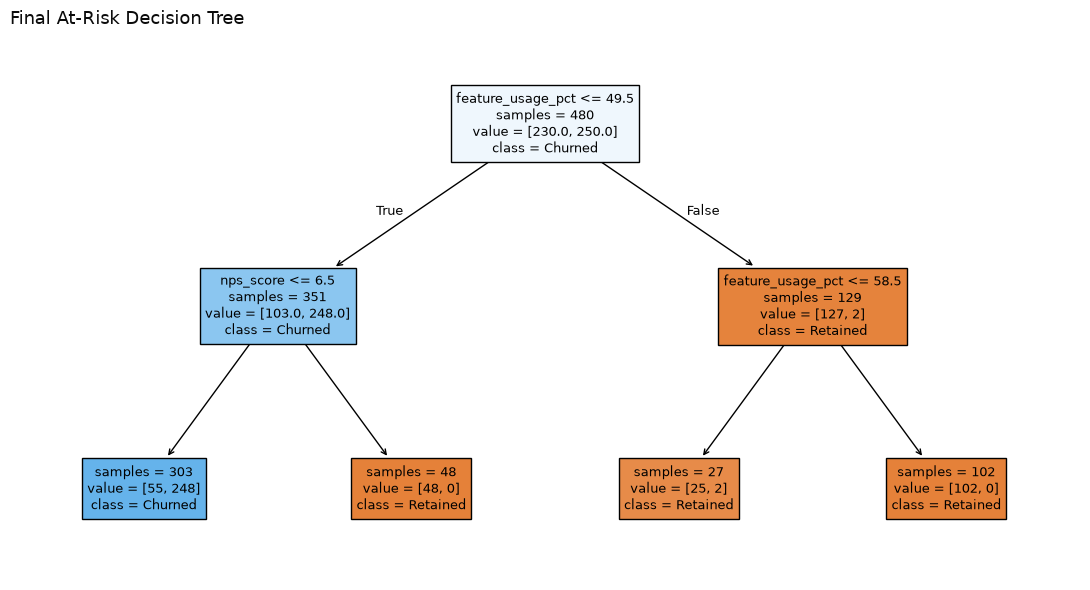

In [13]:
fig, ax = plt.subplots(figsize=(11, 6))
plot_tree(final_tree, feature_names=final_features, class_names=["Retained", "Churned"],
          filled=True, impurity=False, fontsize=9, ax=ax)
ax.set_title("Final At-Risk Decision Tree", fontsize=13, color="#0b0b0b", loc="left")
plt.tight_layout()
plt.show()

## Held-Out Test Performance

Everything above — the stump threshold, the CV comparison between candidate trees, and the final tree's fit — only ever touched the training split. The cell below is the one point where the test split gets used: scoring the already-finalized tree on data it has never seen, in any capacity, until now.

In [14]:
test_pred = final_tree.predict(test_df[final_features])
test_proba = final_tree.predict_proba(test_df[final_features])[:, 1]

print(f"Held-out test accuracy = {accuracy_score(test_df['churned'], test_pred):.3f}")
print(f"Held-out test ROC-AUC  = {roc_auc_score(test_df['churned'], test_proba):.3f}")
print(f"Held-out test F1       = {f1_score(test_df['churned'], test_pred):.3f}")
print()
print(classification_report(test_df["churned"], test_pred, target_names=["Retained", "Churned"]))

Held-out test accuracy = 0.867
Held-out test ROC-AUC  = 0.878
Held-out test F1       = 0.882

              precision    recall  f1-score   support

    Retained       0.94      0.77      0.85        57
     Churned       0.82      0.95      0.88        63

    accuracy                           0.87       120
   macro avg       0.88      0.86      0.86       120
weighted avg       0.88      0.87      0.87       120



## Sizing the At-Risk Bucket

"Current customers" means still-subscribed, not already-churned — so the rule above is applied only to active (`churned = false`) customers to estimate how many are at risk *now*.

In [15]:
%%sql active_customers <<
SELECT feature_usage_pct, nps_score
  FROM subscriptions
 WHERE churned = false;

Running query in 'duckdb://'

In [16]:
active_customers = active_customers.copy()
active_customers["at_risk"] = final_tree.predict(active_customers[final_features]).astype(bool)

at_risk_count = int(active_customers["at_risk"].sum())
active_count = len(active_customers)
at_risk_pct = at_risk_count / active_count

print(f"{at_risk_count} of {active_count} active customers ({at_risk_pct:.1%}) are flagged at-risk")

68 of 287 active customers (23.7%) are flagged at-risk


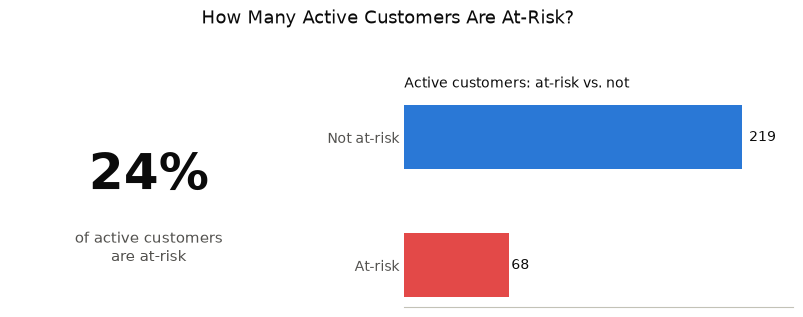

In [17]:
fig = plt.figure(figsize=(9, 3.2))
gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1.4], wspace=0.35, figure=fig)

ax_stat = fig.add_subplot(gs[0])
ax_stat.axis("off")
ax_stat.text(0.5, 0.62, f"{at_risk_pct:.0%}", ha="center", va="center",
             fontsize=36, color="#0b0b0b", fontweight="bold")
ax_stat.text(0.5, 0.28, "of active customers\nare at-risk", ha="center", va="center",
             fontsize=11, color="#52514e")

ax_bar = fig.add_subplot(gs[1])
labels = ["At-risk", "Not at-risk"]
values = [at_risk_count, active_count - at_risk_count]
colors = ["#e34948", "#2a78d6"]
bars = ax_bar.barh(labels, values, color=colors, height=0.5)
for bar, value in zip(bars, values):
    ax_bar.text(bar.get_width() * 1.02, bar.get_y() + bar.get_height() / 2,
                f"{value:,}", va="center", fontsize=10, color="#0b0b0b")
ax_bar.set_title("Active customers: at-risk vs. not", fontsize=10, color="#0b0b0b", loc="left")
for spine in ["top", "right", "left"]:
    ax_bar.spines[spine].set_visible(False)
ax_bar.spines["bottom"].set_color("#c3c2b7")
ax_bar.xaxis.set_visible(False)
ax_bar.tick_params(axis="y", length=0, labelcolor="#52514e", labelsize=10)
ax_bar.margins(x=0.15)

fig.suptitle("How Many Active Customers Are At-Risk?", fontsize=13, color="#0b0b0b", y=1.05)
fig.subplots_adjust(left=0.08, right=0.95, top=0.78, bottom=0.12)
plt.show()

## Summary

- Both predictors separate churn strongly and independently (usage-bin/NPS bars above, and the scatter plot showing essentially no churned customers once usage climbs past ~60%).
- All threshold derivation, model comparison, and the final fit use a training split only (480 of 600 rows, stratified on `churned`); the remaining 120 rows are a held-out test set touched exactly once, at the end.
- The stump's split — **`feature_usage_pct` ≤ 49.5%**, fit on the training split — is a genuinely sharp dividing line, not an arbitrary round number: within the training data, customers above it churn **1.6%** of the time (n=129), while customers at or below it churn **70.7%** of the time (n=351).
- Adding NPS meaningfully improves the model (training-split CV: accuracy 77.3% → 87.5%, ROC-AUC 76.4% → 87.6%, F1 81.9% → 89.2%), and a deeper tree adds essentially nothing (depth 4 ties depth 2 on accuracy/F1, with only a marginal AUC edge not worth the extra complexity). So the **final at-risk rule is `feature_usage_pct ≤ 49.5%` AND `nps_score ≤ 6.5`**, fit on the training split — low usage alone isn't a death sentence if NPS is high enough; it's the combination that marks real risk.
- On the held-out test set — never touched during threshold derivation, model comparison, or fitting — the final rule scores **86.7% accuracy, 87.8% ROC-AUC, 88.2% F1** (94% precision / 77% recall identifying retained customers, 82% precision / 95% recall identifying churned customers), confirming the rule generalizes rather than overfitting the training split.
- Applying that rule to active (`churned = false`) customers only: **68 of 287 (23.7%)** are currently flagged at-risk — roughly 1 in 4 of the current customer base.